# 07 — Generalização, eficiência computacional e tabela comparativa final

**Objetivo:** consolidar a comparação entre as três famílias (especialista, árvore e ensembles), medindo:

1. **Generalização:** gap treino–teste com valores exatos e validação cruzada K=5.
2. **Eficiência:** tempo e pico de memória no treinamento *e* na inferência, tamanho em disco.
3. **Custo energético:** estimativa de energia e CO₂ a partir do tempo medido e de premissas explícitas.
4. **Hardware:** CPU, RAM e sistema operacional usados nas medições.

As métricas vêm dos notebooks 03–06; nada é reestimado "de cabeça".

In [1]:
import sys, json, os, platform, subprocess
from datetime import datetime
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import psutil
import sklearn

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor

from src.config import (
    SEED, CLASSIFICATION_TARGET, REGRESSION_TARGET, RISK_CLASSES,
    REPORTS_DIR, TABLES_DIR, FIGURES_DIR, RULES_DIR,
)
from src.data import split_train_test, encode_target
from src.expert_system import KnowledgeBase, InferenceEngine
from src import metrics, profiling

np.random.seed(SEED)
sns.set_theme(style='whitegrid')
MODELOS_DIR = REPORTS_DIR / 'models'
print('Semente:', SEED)

Semente: 42


## 1) Dados, modelos e sistema especialista

Os modelos de árvore/ensembles são carregados do disco (artefatos dos notebooks 04 e 05). O especialista é reconstruído a partir da base de conhecimento (`rules/`), que é o seu "modelo".

In [2]:
df_reg = pd.read_csv('../data/processed/dataset_regression.csv')
df_clf = pd.read_csv('../data/processed/dataset_classification.csv')

Xr_train, Xr_test, yr_train, yr_test = split_train_test(df_reg, REGRESSION_TARGET, stratify=False)
Xc_train, Xc_test, yc_train_raw, yc_test_raw = split_train_test(df_clf, CLASSIFICATION_TARGET, stratify=True)
yc_train = encode_target(yc_train_raw)
yc_test = encode_target(yc_test_raw)

modelos = {
    'tree_classificacao': joblib.load(MODELOS_DIR / 'tree_classificacao.joblib'),
    'tree_regressao': joblib.load(MODELOS_DIR / 'tree_regressao.joblib'),
    'rf_classificacao': joblib.load(MODELOS_DIR / 'rf_classificacao.joblib'),
    'rf_regressao': joblib.load(MODELOS_DIR / 'rf_regressao.joblib'),
    'gb_classificacao': joblib.load(MODELOS_DIR / 'gb_classificacao.joblib'),
    'gb_regressao': joblib.load(MODELOS_DIR / 'gb_regressao.joblib'),
}

# Garante inferência single-thread para medição comparável
for chave in ['rf_classificacao', 'rf_regressao']:
    modelos[chave].set_params(n_jobs=1)

kb_c = KnowledgeBase.load(RULES_DIR / 'kb_classificacao.csv')
engine_c = InferenceEngine(kb_c)
kb_r = KnowledgeBase.load(RULES_DIR / 'kb_regressao.csv')
kb_r = KnowledgeBase.load_metadata(kb_r, RULES_DIR / 'kb_metadata.json')
engine_r = InferenceEngine(kb_r)

print('Modelos carregados:', list(modelos))
print('Regras — classificação:', len(kb_c.by_problem('classificacao')), '| regressão:', len(kb_r.by_problem('regressao')))

Modelos carregados: ['tree_classificacao', 'tree_regressao', 'rf_classificacao', 'rf_regressao', 'gb_classificacao', 'gb_regressao']
Regras — classificação: 19 | regressão: 16


## 2) Especificações de hardware

Registra-se a máquina em que **todas** as medições foram feitas. Sem isso, tempos e memória não são comparáveis com outros trabalhos.

In [3]:
def nome_cpu():
    try:
        saida = subprocess.check_output(['wmic', 'cpu', 'get', 'name'], text=True)
        linhas = [l.strip() for l in saida.splitlines() if l.strip() and l.strip().lower() != 'name']
        if linhas:
            return linhas[0]
    except Exception:
        pass
    return platform.processor() or 'Não identificado'

hardware = {
    'Sistema operacional': f'{platform.system()} {platform.release()} ({platform.version()})',
    'Arquitetura': platform.machine(),
    'CPU': nome_cpu(),
    'Nucleos logicos': psutil.cpu_count(logical=True),
    'Nucleos fisicos': psutil.cpu_count(logical=False),
    'RAM total (GB)': round(psutil.virtual_memory().total / (1024 ** 3), 2),
    'Python': platform.python_version(),
    'scikit-learn': sklearn.__version__,
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'Data da medicao': datetime.now().strftime('%Y-%m-%d %H:%M'),
}
(MODELOS_DIR / '07_hardware.json').write_text(json.dumps(hardware, indent=2, ensure_ascii=False), encoding='utf-8')
pd.Series(hardware).to_frame('Valor')

,Valor
Sistema operacional,Windows 10 (10.0.26200)
Arquitetura,AMD64
CPU,"Intel64 Family 6 Model 142 Stepping 12, Genuin..."
Nucleos logicos,8
Nucleos fisicos,4
RAM total (GB),7.83
Python,3.9.13
scikit-learn,1.6.1
pandas,2.3.3
numpy,2.0.2


## 3) Tamanho dos modelos em disco

O "modelo" do especialista é a base de conhecimento (CSV + texto). Para árvore e ensembles, mede-se o arquivo `joblib` comprimido. O tamanho é um critério de viabilidade em produção (deploy, memória, versionamento).

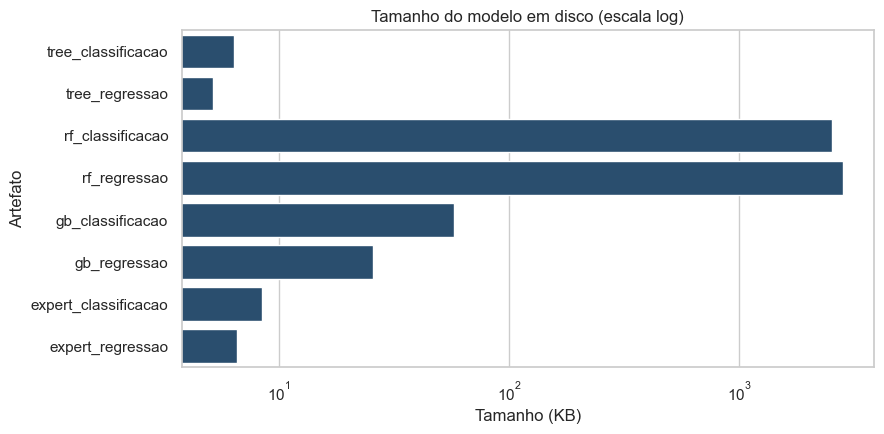

,Artefato,Tamanho (KB)
0,tree_classificacao,6.369
1,tree_regressao,5.165
2,rf_classificacao,2542.409
3,rf_regressao,2819.360
4,gb_classificacao,57.480
5,gb_regressao,25.744
6,expert_classificacao,8.454
7,expert_regressao,6.544


In [4]:
tamanhos = []
for chave in ['tree_classificacao', 'tree_regressao', 'rf_classificacao', 'rf_regressao', 'gb_classificacao', 'gb_regressao']:
    caminho = MODELOS_DIR / f'{chave}.joblib'
    tamanhos.append({'Artefato': chave, 'Tamanho (KB)': os.path.getsize(caminho) / 1024})

tam_kb_c = os.path.getsize(RULES_DIR / 'kb_classificacao.csv') / 1024 + os.path.getsize(RULES_DIR / 'regras_classificacao.txt') / 1024
tam_kb_r = os.path.getsize(RULES_DIR / 'kb_regressao.csv') / 1024 + os.path.getsize(RULES_DIR / 'regras_regressao.txt') / 1024
tamanhos.append({'Artefato': 'expert_classificacao', 'Tamanho (KB)': tam_kb_c})
tamanhos.append({'Artefato': 'expert_regressao', 'Tamanho (KB)': tam_kb_r})

tamanhos = pd.DataFrame(tamanhos)
tamanhos.to_csv(TABLES_DIR / '07_tamanho_disco.csv', index=False)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=tamanhos, x='Tamanho (KB)', y='Artefato', color='#1f4e79')
plt.xscale('log')
plt.title('Tamanho do modelo em disco (escala log)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '07_tamanho_modelos.png', dpi=200, bbox_inches='tight')
plt.show()
tamanhos.round(3)

## 4) Medição do treinamento (tempo e memória)

Para comparar de forma justa, o treinamento é refeito **single-thread** (`n_jobs=1`) em todos os modelos. O pico de memória é medido com `tracemalloc` (alocações Python no processo). Modelos paralelos teriam pico agregado maior que o medido — por isso a padronização single-thread.

O especialista não tem etapa de treinamento estatístico: o esforço humano (cronômetro) é reportado na seção 8.

In [5]:
tree_params = json.loads((MODELOS_DIR / 'tree_params.json').read_text(encoding='utf-8'))
ensemble_meta = json.loads((MODELOS_DIR / 'ensemble_meta.json').read_text(encoding='utf-8'))

p = tree_params['classificacao']
p_r = tree_params['regressao']
rf_c_params = {k: v for k, v in ensemble_meta['rf_classificacao'].items() if k != 'n_estimators'}
rf_r_params = {k: v for k, v in ensemble_meta['rf_regressao'].items() if k != 'n_estimators'}

construtores = {
    'tree_classificacao': lambda: DecisionTreeClassifier(random_state=SEED, **p).fit(Xc_train, yc_train),
    'tree_regressao': lambda: DecisionTreeRegressor(random_state=SEED, **p_r).fit(Xr_train, yr_train),
    'rf_classificacao': lambda: RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1, **rf_c_params).fit(Xc_train, yc_train),
    'rf_regressao': lambda: RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=1, **rf_r_params).fit(Xr_train, yr_train),
    'gb_classificacao': lambda: GradientBoostingClassifier(random_state=SEED, **ensemble_meta['gb_classificacao']).fit(Xc_train, yc_train),
    'gb_regressao': lambda: GradientBoostingRegressor(random_state=SEED, **ensemble_meta['gb_regressao']).fit(Xr_train, yr_train),
}

linhas_treino = []
for chave, construtor in construtores.items():
    perfil = profiling.profile_training(construtor)
    linhas_treino.append({
        'Artefato': chave,
        'Tempo treino (s)': perfil['tempo_treinamento_s'],
        'Pico memoria treino (MB)': perfil['pico_memoria_treinamento_mb'],
        'Pico memoria treino (KB)': perfil['pico_memoria_treinamento_kb'],
    })
    print(f"{chave}: {perfil['tempo_treinamento_s']:.2f} s | {perfil['pico_memoria_treinamento_mb']:.1f} MB")

treinamento = pd.DataFrame(linhas_treino)
treinamento.to_csv(TABLES_DIR / '07_treinamento.csv', index=False)
treinamento.round(3)

tree_classificacao: 0.86 s | 38.9 MB


tree_regressao: 0.67 s | 38.9 MB


rf_classificacao: 37.87 s | 38.9 MB


rf_regressao: 79.57 s | 38.9 MB


gb_classificacao: 70.73 s | 38.9 MB


gb_regressao: 23.39 s | 38.9 MB


,Artefato,Tempo treino (s),Pico memoria treino (MB),Pico memoria treino (KB)
0,tree_classificacao,0.859,38.943,39877.890
1,tree_regressao,0.665,38.921,39854.674
2,rf_classificacao,37.872,38.923,39856.674
3,rf_regressao,79.575,38.918,39851.564
4,gb_classificacao,70.727,38.919,39852.676
5,gb_regressao,23.388,38.915,39849.330


## 5) Medição da inferência (tempo e memória)

Inferência = previsão sobre o conjunto de teste (10.000 amostras), repetida 30 vezes. Reporta-se média, desvio-padrão, tempo por amostra, vazão e pico de memória. O tempo do especialista inclui a avaliação vetorizada de todas as regras.

In [6]:
predicoes = {
    'expert_classificacao': lambda X: engine_c.predict_classification(X),
    'expert_regressao': lambda X: engine_r.predict_regression(X),
    'tree_classificacao': modelos['tree_classificacao'].predict,
    'tree_regressao': modelos['tree_regressao'].predict,
    'rf_classificacao': modelos['rf_classificacao'].predict,
    'rf_regressao': modelos['rf_regressao'].predict,
    'gb_classificacao': modelos['gb_classificacao'].predict,
    'gb_regressao': modelos['gb_regressao'].predict,
}

linhas_inf = []
for chave, funcao in predicoes.items():
    X = Xc_test if chave.endswith('classificacao') else Xr_test
    perfil = profiling.profile_inference(funcao, X, n_rep=30)
    linhas_inf.append({
        'Artefato': chave,
        'Tempo medio (s)': perfil.tempo_medio_s,
        'Desvio padrao (s)': perfil.tempo_desvio_s,
        'Tempo por amostra (ms)': perfil.tempo_por_amostra_ms,
        'Vazao (amostras/s)': perfil.vazao_amostras_por_s,
        'Pico memoria inferencia (KB)': perfil.pico_memoria_kb,
        'Pico memoria inferencia (MB)': perfil.pico_memoria_mb,
    })
    print(f"{chave}: {perfil.tempo_medio_s*1000:.2f} ms | {perfil.tempo_por_amostra_ms:.5f} ms/amostra | {perfil.pico_memoria_kb:.1f} KB")

inferencia = pd.DataFrame(linhas_inf)
inferencia.to_csv(TABLES_DIR / '07_inferencia.csv', index=False)
inferencia.round(6)

expert_classificacao: 116.68 ms | 0.01167 ms/amostra | 649.4 KB


expert_regressao: 24.85 ms | 0.00249 ms/amostra | 253.3 KB


tree_classificacao: 21.72 ms | 0.00217 ms/amostra | 9971.5 KB


tree_regressao: 18.07 ms | 0.00181 ms/amostra | 9966.9 KB


rf_classificacao: 270.25 ms | 0.02703 ms/amostra | 10097.7 KB


rf_regressao: 305.66 ms | 0.03057 ms/amostra | 10096.7 KB


gb_classificacao: 145.67 ms | 0.01457 ms/amostra | 9972.6 KB


gb_regressao: 60.62 ms | 0.00606 ms/amostra | 9969.4 KB


,Artefato,Tempo medio (s),Desvio padrao (s),Tempo por amostra (ms),Vazao (amostras/s),Pico memoria inferencia (KB),Pico memoria inferencia (MB)
0,expert_classificacao,0.116681,0.029760,0.011668,85703.487075,649.425781,0.634205
1,expert_regressao,0.024853,0.005163,0.002485,402367.530550,253.349609,0.247412
2,tree_classificacao,0.021720,0.009279,0.002172,460406.216405,9971.511719,9.737804
3,tree_regressao,0.018073,0.002648,0.001807,553306.671329,9966.907227,9.733308
4,rf_classificacao,0.270254,0.038197,0.027025,37002.250810,10097.687500,9.861023
5,rf_regressao,0.305660,0.037238,0.030566,32716.105115,10096.713867,9.860072
6,gb_classificacao,0.145668,0.039421,0.014567,68649.437870,9972.582031,9.738850
7,gb_regressao,0.060624,0.013345,0.006062,164952.199327,9969.430664,9.735772


## 6) Estimativa de energia e CO₂

**Premissas explícitas** (documentadas para permitir recálculo):

- Potência média da CPU durante a carga: **45 W** (faixa típica de processador de notebook; não é medição de hardware dedicado).
- Intensidade de carbono da rede elétrica brasileira: **0,0817 kgCO₂/kWh** (média recente do SIN).
- PUE = 1,0 (execução local, sem refrigeração de data center).
- Energia = potência × tempo medido. Para inferência, reporta-se o custo por **1.000 predições**.

Essas estimativas são **ordens de grandeza**, não medições de consumo no wall-plug.

In [7]:
TDP_W = 45.0
CARBONO_KG_POR_KWH = 0.0817

def energia_wh(tempo_s):
    return TDP_W * tempo_s / 3600.0

def co2_g(energia_wh):
    return energia_wh / 1000.0 * CARBONO_KG_POR_KWH * 1000.0

energia = treinamento.merge(inferencia, on='Artefato', how='outer')
energia['Energia treino (Wh)'] = energia['Tempo treino (s)'].apply(lambda t: energia_wh(t) if pd.notna(t) else 0.0)
energia['CO2 treino (g)'] = energia['Energia treino (Wh)'].apply(co2_g)
energia['Energia inferencia/1000 (Wh)'] = energia['Tempo por amostra (ms)'].apply(lambda ms: energia_wh(ms * 1000 / 1000))
energia['CO2 inferencia/1000 (g)'] = energia['Energia inferencia/1000 (Wh)'].apply(co2_g)

energia = energia[['Artefato', 'Energia treino (Wh)', 'CO2 treino (g)',
                   'Energia inferencia/1000 (Wh)', 'CO2 inferencia/1000 (g)']]
energia.to_csv(TABLES_DIR / '07_energia.csv', index=False)
energia.round(6)

,Artefato,Energia treino (Wh),CO2 treino (g),Energia inferencia/1000 (Wh),CO2 inferencia/1000 (g)
0,expert_classificacao,0.000000,0.000000,0.000146,0.000012
1,expert_regressao,0.000000,0.000000,0.000031,0.000003
2,gb_classificacao,0.884092,0.072230,0.000182,0.000015
3,gb_regressao,0.292355,0.023885,0.000076,0.000006
4,rf_classificacao,0.473394,0.038676,0.000338,0.000028
5,rf_regressao,0.994684,0.081266,0.000382,0.000031
6,tree_classificacao,0.010741,0.000878,0.000027,0.000002
7,tree_regressao,0.008319,0.000680,0.000023,0.000002


## 7) Curvas de generalização e eficiência

- **Desempenho × custo de treino:** mostra o trade-off entre qualidade e tempo.
- **Gap:** degradação treino→teste (F1 para classificação, RMSE para regressão).
- **Memória:** pico na inferência (o que importa em produção).

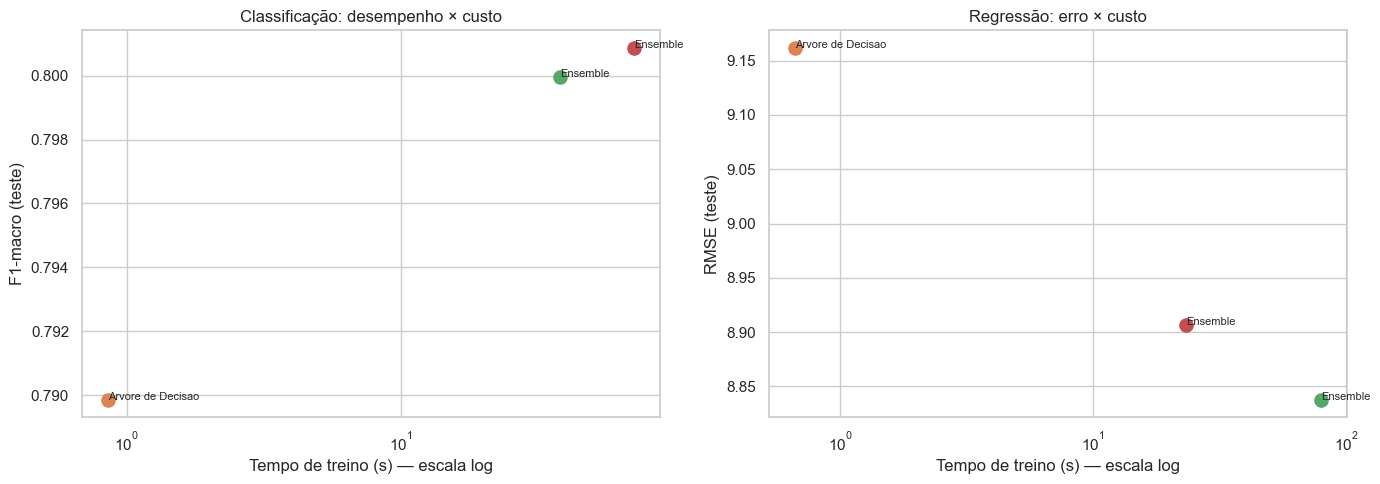

In [8]:
resumo_clf = pd.read_csv(TABLES_DIR / '06_resumo_classificacao.csv')
resumo_reg = pd.read_csv(TABLES_DIR / '06_resumo_regressao.csv')
resumo_clf['Problema'] = 'Classificacao'
resumo_reg['Problema'] = 'Regressao'
gaps = pd.read_csv(TABLES_DIR / '06_gaps_exatos.csv')

mapa_artefato = {
    'Sistema Especialista': 'expert',
    'Arvore de Decisao': 'tree',
    'Ensemble (Random Forest)': 'rf',
    'Ensemble (Gradient Boosting)': 'gb',
}

def custo_treino(familia, problema):
    prefixo = mapa_artefato[familia]
    chave = f'{prefixo}_{"classificacao" if problema == "Classificacao" else "regressao"}'
    linha = treinamento[treinamento['Artefato'] == chave]
    return float(linha['Tempo treino (s)'].iloc[0]) if len(linha) else np.nan

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for _, linha in resumo_clf.iterrows():
    tempo = custo_treino(linha['Familia'], 'Classificacao')
    axes[0].scatter(tempo, linha['F1 (macro)'], s=90)
    axes[0].annotate(linha['Familia'].split(' (')[0], (tempo, linha['F1 (macro)']), fontsize=8)
axes[0].set_xlabel('Tempo de treino (s) — escala log'); axes[0].set_ylabel('F1-macro (teste)')
axes[0].set_xscale('log'); axes[0].set_title('Classificação: desempenho × custo')

for _, linha in resumo_reg.iterrows():
    tempo = custo_treino(linha['Familia'], 'Regressao')
    axes[1].scatter(tempo, linha['RMSE'], s=90)
    axes[1].annotate(linha['Familia'].split(' (')[0], (tempo, linha['RMSE']), fontsize=8)
axes[1].set_xlabel('Tempo de treino (s) — escala log'); axes[1].set_ylabel('RMSE (teste)')
axes[1].set_xscale('log'); axes[1].set_title('Regressão: erro × custo')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '07_desempenho_vs_custo.png', dpi=200, bbox_inches='tight')
plt.show()

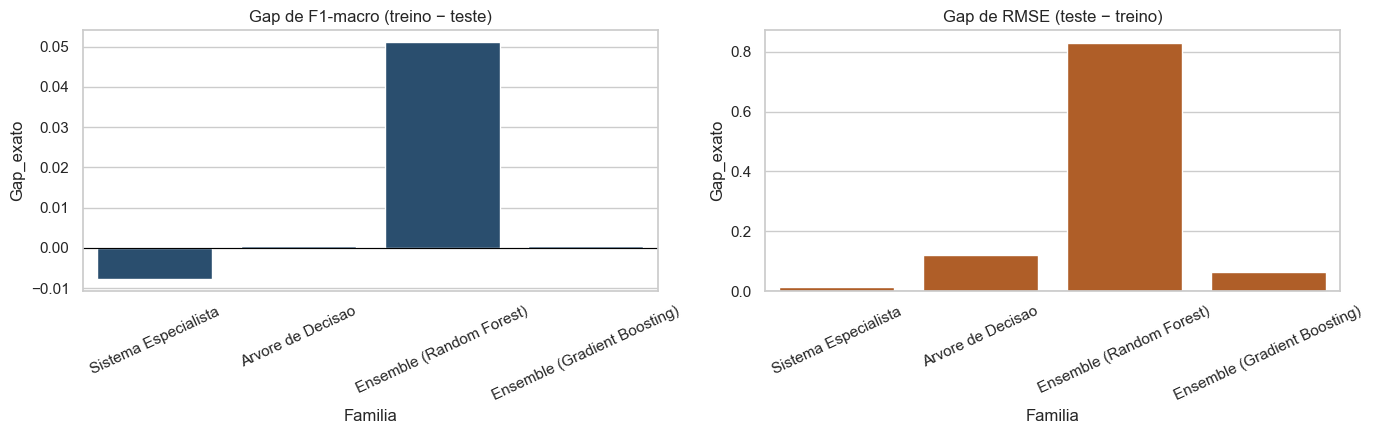

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
gaps_c = gaps[gaps['Problema'] == 'Classificacao']
gaps_r = gaps[gaps['Problema'] == 'Regressao']

sns.barplot(data=gaps_c, x='Familia', y='Gap_exato', ax=axes[0], color='#1f4e79')
axes[0].set_title('Gap de F1-macro (treino − teste)')
axes[0].tick_params(axis='x', rotation=25)
axes[0].axhline(0, color='black', linewidth=0.8)

sns.barplot(data=gaps_r, x='Familia', y='Gap_exato', ax=axes[1], color='#c55a11')
axes[1].set_title('Gap de RMSE (teste − treino)')
axes[1].tick_params(axis='x', rotation=25)
axes[1].axhline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '07_gaps_generalizacao.png', dpi=200, bbox_inches='tight')
plt.show()

## 8) Esforço humano (cronômetro)

O esforço humano é um custo **da família especialista** e não é comparável a tempo de CPU. Ele é mostrado separadamente para não distorcer a análise computacional.

In [10]:
cronometro = pd.read_csv('../logs/cronometro_regras.csv')
esforco = cronometro.groupby('problema').agg(
    Sessoes=('tempo_total_min', 'size'),
    Tempo_total_min=('tempo_total_min', 'sum'),
    Media_min=('tempo_total_min', 'mean'),
    Desvio_min=('tempo_total_min', 'std'),
    Regras=('n_regras_criadas', 'sum'),
)
esforco['Tempo_por_regra_min'] = esforco['Tempo_total_min'] / esforco['Regras']
esforco.to_csv(TABLES_DIR / '07_esforco_humano.csv')
esforco.round(2)

,Sessoes,Tempo_total_min,Media_min,Desvio_min,Regras,Tempo_por_regra_min
problema,,,,,,
classificacao,3,127.0,42.33,3.79,19,6.68
regressao,3,115.0,38.33,2.08,16,7.19


## 9) Tabela comparativa final

Duas tabelas (classificação e regressão) com **todas** as métricas exigidas, gap exato, CV K=5 e eficiência. Elas alimentam diretamente a seção 6.2 do relatório.

In [11]:
cv = pd.read_csv(TABLES_DIR / '06_validacao_cruzada.csv')
cv_clf = cv[(cv['Problema'] == 'Classificacao') & (cv['Metrica'] == 'F1_macro')].set_index('Familia')
cv_reg = cv[(cv['Problema'] == 'Regressao') & (cv['Metrica'] == 'RMSE')].set_index('Familia')

def eficiencia(familia, problema):
    prefixo = mapa_artefato[familia]
    chave = f'{prefixo}_{"classificacao" if problema == "Classificacao" else "regressao"}'
    t = treinamento[treinamento['Artefato'] == chave]
    i = inferencia[inferencia['Artefato'] == chave]
    s = tamanhos[tamanhos['Artefato'] == chave]
    e = energia[energia['Artefato'] == chave]
    return {
        'Tempo treino (s)': float(t['Tempo treino (s)'].iloc[0]) if len(t) else np.nan,
        'Pico memoria treino (MB)': float(t['Pico memoria treino (MB)'].iloc[0]) if len(t) else np.nan,
        'Tempo por amostra (ms)': float(i['Tempo por amostra (ms)'].iloc[0]) if len(i) else np.nan,
        'Pico memoria inferencia (KB)': float(i['Pico memoria inferencia (KB)'].iloc[0]) if len(i) else np.nan,
        'Tamanho disco (KB)': float(s['Tamanho (KB)'].iloc[0]) if len(s) else np.nan,
        'Energia treino (Wh)': float(e['Energia treino (Wh)'].iloc[0]) if len(e) else np.nan,
        'CO2 treino (g)': float(e['CO2 treino (g)'].iloc[0]) if len(e) else np.nan,
        'Energia inferencia/1000 (Wh)': float(e['Energia inferencia/1000 (Wh)'].iloc[0]) if len(e) else np.nan,
        'CO2 inferencia/1000 (g)': float(e['CO2 inferencia/1000 (g)'].iloc[0]) if len(e) else np.nan,
    }

def complexidade(familia, problema):
    if familia == 'Sistema Especialista':
        n = len(kb_c.by_problem('classificacao')) if problema == 'Classificacao' else len(kb_r.by_problem('regressao'))
        return f'{n} regras SE-ENTAO'
    if familia == 'Arvore de Decisao':
        d = tree_params['profundidade']['classificacao' if problema == 'Classificacao' else 'regressao']
        f = tree_params['folhas']['classificacao' if problema == 'Classificacao' else 'regressao']
        return f'profundidade {d}, {f} folhas'
    return '100 arvores'

def esforco_humano(familia, problema):
    if familia != 'Sistema Especialista':
        return np.nan
    return float(esforco.loc['classificacao' if problema == 'Classificacao' else 'regressao', 'Tempo_total_min'])

tabela_clf = resumo_clf.copy()
tabela_clf['Familia'] = tabela_clf['Familia']
for coluna in ['Tempo treino (s)', 'Pico memoria treino (MB)', 'Tempo por amostra (ms)',
               'Pico memoria inferencia (KB)', 'Tamanho disco (KB)', 'Energia treino (Wh)',
               'CO2 treino (g)', 'Energia inferencia/1000 (Wh)', 'CO2 inferencia/1000 (g)']:
    tabela_clf[coluna] = tabela_clf.apply(lambda r: eficiencia(r['Familia'], r['Problema'])[coluna], axis=1)
tabela_clf['CV F1-macro (media)'] = tabela_clf['Familia'].map(cv_clf['Media'])
tabela_clf['CV F1-macro (dp)'] = tabela_clf['Familia'].map(cv_clf['Desvio_padrao'])
tabela_clf['Esforco humano (min)'] = tabela_clf.apply(lambda r: esforco_humano(r['Familia'], r['Problema']), axis=1)
tabela_clf['Complexidade'] = tabela_clf.apply(lambda r: complexidade(r['Familia'], r['Problema']), axis=1)

tabela_reg = resumo_reg.copy()
for coluna in ['Tempo treino (s)', 'Pico memoria treino (MB)', 'Tempo por amostra (ms)',
               'Pico memoria inferencia (KB)', 'Tamanho disco (KB)', 'Energia treino (Wh)',
               'CO2 treino (g)', 'Energia inferencia/1000 (Wh)', 'CO2 inferencia/1000 (g)']:
    tabela_reg[coluna] = tabela_reg.apply(lambda r: eficiencia(r['Familia'], r['Problema'])[coluna], axis=1)
tabela_reg['CV RMSE (media)'] = tabela_reg['Familia'].map(cv_reg['Media'])
tabela_reg['CV RMSE (dp)'] = tabela_reg['Familia'].map(cv_reg['Desvio_padrao'])
tabela_reg['Esforco humano (min)'] = tabela_reg.apply(lambda r: esforco_humano(r['Familia'], r['Problema']), axis=1)
tabela_reg['Complexidade'] = tabela_reg.apply(lambda r: complexidade(r['Familia'], r['Problema']), axis=1)

tabela_clf.to_csv(TABLES_DIR / 'comparativo_classificacao.csv', index=False)
tabela_reg.to_csv(TABLES_DIR / 'comparativo_regressao.csv', index=False)

print('TABELA 2a — CLASSIFICAÇÃO')
display(tabela_clf.round(4))
print('TABELA 2b — REGRESSÃO')
display(tabela_reg.round(4))

TABELA 2a — CLASSIFICAÇÃO


,Familia,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OVR macro),PR-AUC (macro),Gap F1 (macro),Problema,Tempo treino (s),...,Pico memoria inferencia (KB),Tamanho disco (KB),Energia treino (Wh),CO2 treino (g),Energia inferencia/1000 (Wh),CO2 inferencia/1000 (g),CV F1-macro (media),CV F1-macro (dp),Esforco humano (min),Complexidade
0,Sistema Especialista,0.7987,0.7913,0.7986,0.7907,0.8884,0.7796,-0.0078,Classificacao,NaN,...,649.4258,8.4541,0.0000,0.0000,0.0001,0.0,NaN,NaN,127.0,19 regras SE-ENTAO
1,Arvore de Decisao,0.8096,0.8066,0.7798,0.7899,0.9417,0.8498,0.0004,Classificacao,0.8593,...,9971.5117,6.3691,0.0107,0.0009,0.0000,0.0,0.7870,0.0033,NaN,"profundidade 6, 64 folhas"
2,Ensemble (Random Forest),0.8179,0.8048,0.7966,0.8000,0.9463,0.8653,0.0511,Classificacao,37.8715,...,10097.6875,2542.4092,0.4734,0.0387,0.0003,0.0,0.7962,0.0045,NaN,100 arvores
3,Ensemble (Gradient Boosting),0.8187,0.8056,0.7976,0.8009,0.9469,0.8671,0.0005,Classificacao,70.7274,...,9972.5820,57.4805,0.8841,0.0722,0.0002,0.0,0.7966,0.0038,NaN,100 arvores


TABELA 2b — REGRESSÃO


,Familia,MAE,MSE,RMSE,MAPE (%),R²,MedAE,Gap RMSE,Problema,Tempo treino (s),...,Pico memoria inferencia (KB),Tamanho disco (KB),Energia treino (Wh),CO2 treino (g),Energia inferencia/1000 (Wh),CO2 inferencia/1000 (g),CV RMSE (media),CV RMSE (dp),Esforco humano (min),Complexidade
0,Sistema Especialista,13.1626,250.6768,15.8328,92.5491,0.6367,11.9892,0.0144,Regressao,NaN,...,253.3496,6.5439,0.0000,0.0000,0.0000,0.0,NaN,NaN,115.0,16 regras SE-ENTAO
1,Arvore de Decisao,7.7679,83.9369,9.1617,39.0485,0.8784,7.2214,0.1214,Regressao,0.6655,...,9966.9072,5.1650,0.0083,0.0007,0.0000,0.0,9.1756,0.0770,NaN,"profundidade 6, 64 folhas"
2,Ensemble (Random Forest),7.5587,78.1057,8.8377,37.8820,0.8868,7.1666,0.8302,Regressao,79.5747,...,10096.7139,2819.3604,0.9947,0.0813,0.0004,0.0,8.8519,0.0628,NaN,100 arvores
3,Ensemble (Gradient Boosting),7.6073,79.3224,8.9063,37.8968,0.8850,7.2081,0.0625,Regressao,23.3884,...,9969.4307,25.7441,0.2924,0.0239,0.0001,0.0,8.9115,0.0496,NaN,100 arvores


## 10) Tabela longa consolidada (`comparativo_final.csv`)

Formato longo (uma linha por modelo × problema) usado pelo gerador do relatório. Mantém as colunas antigas e acrescenta as métricas que faltavam.

In [12]:
metricas_clf_full = pd.read_csv(TABLES_DIR / '06_metricas_classificacao.csv')
metricas_reg_full = pd.read_csv(TABLES_DIR / '06_metricas_regressao.csv')

def treino_clf(familia):
    linha = metricas_clf_full[(metricas_clf_full['Familia'] == familia) & (metricas_clf_full['Conjunto'] == 'Treino')]
    return linha.iloc[0] if len(linha) else None

def treino_reg(familia):
    linha = metricas_reg_full[(metricas_reg_full['Familia'] == familia) & (metricas_reg_full['Conjunto'] == 'Treino')]
    return linha.iloc[0] if len(linha) else None

linhas = []
for _, r in tabela_clf.iterrows():
    tr = treino_clf(r['Familia'])
    linhas.append({
        'Familia': r['Familia'], 'Modelo': r['Familia'], 'Problema': 'Classificacao',
        'Metrica treino': f"F1-macro={tr['F1 (macro)']:.4f}" if tr is not None else '',
        'Metrica teste': f"F1-macro={r['F1 (macro)']:.4f}",
        'F1-macro treino': float(tr['F1 (macro)']) if tr is not None else np.nan,
        'Accuracy treino': float(tr['Accuracy']) if tr is not None else np.nan,
        'RMSE teste': np.nan, 'MSE teste': np.nan, 'MAE teste': np.nan,
        'MAPE teste': np.nan, 'R2 teste': np.nan, 'MedAE teste': np.nan,
        'Accuracy teste': r['Accuracy'], 'F1-macro teste': r['F1 (macro)'],
        'Precision macro teste': r['Precision (macro)'], 'Recall macro teste': r['Recall (macro)'],
        'ROC-AUC teste': r['ROC-AUC (OVR macro)'], 'PR-AUC teste': r['PR-AUC (macro)'],
        'Gap F1 (treino-teste)': r['Gap F1 (macro)'],
        'Tempo treino (s)': r['Tempo treino (s)'],
        'Tempo por amostra (ms)': r['Tempo por amostra (ms)'],
        'Pico mem treino (KB)': r['Pico memoria treino (MB)'] * 1024 if pd.notna(r['Pico memoria treino (MB)']) else np.nan,
        'Pico mem inferencia (KB)': r['Pico memoria inferencia (KB)'],
        'Tamanho disco (KB)': r['Tamanho disco (KB)'],
        'Esforco humano (min)': r['Esforco humano (min)'],
        'Num regras/profundidade': r['Complexidade'],
        'CV metrica': 'F1-macro', 'CV media': r['CV F1-macro (media)'], 'CV dp': r['CV F1-macro (dp)'],
        'Energia treino (Wh)': r['Energia treino (Wh)'], 'CO2 treino (g)': r['CO2 treino (g)'],
        'Energia inferencia/1000 (Wh)': r['Energia inferencia/1000 (Wh)'],
        'CO2 inferencia/1000 (g)': r['CO2 inferencia/1000 (g)'],
    })
for _, r in tabela_reg.iterrows():
    tr = treino_reg(r['Familia'])
    linhas.append({
        'Familia': r['Familia'], 'Modelo': r['Familia'], 'Problema': 'Regressao',
        'Metrica treino': f"RMSE={tr['RMSE']:.4f}" if tr is not None else '',
        'Metrica teste': f"RMSE={r['RMSE']:.4f}",
        'F1-macro treino': np.nan, 'Accuracy treino': np.nan,
        'RMSE teste': r['RMSE'], 'MAE teste': r['MAE'], 'MSE teste': r['MSE'],
        'MAPE teste': r['MAPE (%)'], 'R2 teste': r['R²'], 'MedAE teste': r['MedAE'],
        'Accuracy teste': np.nan, 'F1-macro teste': np.nan,
        'Precision macro teste': np.nan, 'Recall macro teste': np.nan,
        'ROC-AUC teste': np.nan, 'PR-AUC teste': np.nan,
        'Gap RMSE (treino-teste)': r['Gap RMSE'],
        'Tempo treino (s)': r['Tempo treino (s)'],
        'Tempo por amostra (ms)': r['Tempo por amostra (ms)'],
        'Pico mem treino (KB)': r['Pico memoria treino (MB)'] * 1024 if pd.notna(r['Pico memoria treino (MB)']) else np.nan,
        'Pico mem inferencia (KB)': r['Pico memoria inferencia (KB)'],
        'Tamanho disco (KB)': r['Tamanho disco (KB)'],
        'Esforco humano (min)': r['Esforco humano (min)'],
        'Num regras/profundidade': r['Complexidade'],
        'CV metrica': 'RMSE', 'CV media': r['CV RMSE (media)'], 'CV dp': r['CV RMSE (dp)'],
        'Energia treino (Wh)': r['Energia treino (Wh)'], 'CO2 treino (g)': r['CO2 treino (g)'],
        'Energia inferencia/1000 (Wh)': r['Energia inferencia/1000 (Wh)'],
        'CO2 inferencia/1000 (g)': r['CO2 inferencia/1000 (g)'],
    })

comparativo_final = pd.DataFrame(linhas)
comparativo_final.to_csv(TABLES_DIR / 'comparativo_final.csv', index=False)
print('comparativo_final.csv gerado com', len(comparativo_final), 'linhas e', comparativo_final.shape[1], 'colunas')
comparativo_final[['Familia', 'Problema', 'Metrica treino', 'Metrica teste', 'Tempo treino (s)', 'Tempo por amostra (ms)', 'Tamanho disco (KB)']].round(4)

comparativo_final.csv gerado com 8 linhas e 35 colunas


,Familia,Problema,Metrica treino,Metrica teste,Tempo treino (s),Tempo por amostra (ms),Tamanho disco (KB)
0,Sistema Especialista,Classificacao,F1-macro=0.7829,F1-macro=0.7907,NaN,0.0117,8.4541
1,Arvore de Decisao,Classificacao,F1-macro=0.7903,F1-macro=0.7899,0.8593,0.0022,6.3691
2,Ensemble (Random Forest),Classificacao,F1-macro=0.8510,F1-macro=0.8000,37.8715,0.0270,2542.4092
3,Ensemble (Gradient Boosting),Classificacao,F1-macro=0.8013,F1-macro=0.8009,70.7274,0.0146,57.4805
4,Sistema Especialista,Regressao,RMSE=15.8184,RMSE=15.8328,NaN,0.0025,6.5439
5,Arvore de Decisao,Regressao,RMSE=9.0403,RMSE=9.1617,0.6655,0.0018,5.1650
6,Ensemble (Random Forest),Regressao,RMSE=8.0075,RMSE=8.8377,79.5747,0.0306,2819.3604
7,Ensemble (Gradient Boosting),Regressao,RMSE=8.8438,RMSE=8.9063,23.3884,0.0061,25.7441


## 11) Discussão final — viés × variância e escolha do modelo

- **Sistema especialista:** não tem *gap* de treino (as regras são fixas), mas erra mais. É o mais auditável e o único cujo custo principal é **humano** (≈4 h de cronômetro), não computacional.
- **Árvore de decisão:** excelente custo-benefício, porém o modelo sem poda memoriza o treino (F1 = 1,0, *gap* ≈ 0,27). A poda recupera generalização.
- **Random Forest:** reduz variância pela média de muitas árvores; obtém o melhor RMSE de teste, mas mantém *gap* alto (≈0,83 no RMSE e ≈0,051 no F1) e é o mais pesado em disco.
- **Gradient Boosting:** árvores rasas + aprendizado sequencial controlam o viés sem explodir a variância; é o mais equilibrado em generalização (*gap* ≈ 0,0005 no F1 e ≈ 0,062 no RMSE), ao custo de maior tempo de treino.
- **Eficiência:** a árvore é a mais rápida e leve; o especialista tem inferência barata, mas alto custo humano; os ensembles pagam em memória/tempo pelo desempenho.
- **Conclusão:** para produção com restrição de latência/memória, árvore podada; para máxima acurácia com generalização estável, Gradient Boosting; para transparência normativa, sistema especialista.

In [13]:
# Ficha resumo da execução (auditoria)
resumo_execucao = {
    'notebook': '07_generalization_efficiency',
    'data_execucao': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'hardware': hardware,
    'modelos': list(modelos),
    'regras_classificacao': len(kb_c.by_problem('classificacao')),
    'regras_regressao': len(kb_r.by_problem('regressao')),
    'arquivos_gerados': [
        'comparativo_classificacao.csv', 'comparativo_regressao.csv', 'comparativo_final.csv',
        '07_treinamento.csv', '07_inferencia.csv', '07_tamanho_disco.csv', '07_energia.csv',
        '07_esforco_humano.csv',
    ],
}
(MODELOS_DIR / '07_resumo_execucao.json').write_text(json.dumps(resumo_execucao, indent=2, ensure_ascii=False), encoding='utf-8')
pd.Series(resumo_execucao).to_frame('valor')

,valor
notebook,07_generalization_efficiency
data_execucao,2026-10-25 20:58
hardware,{'Sistema operacional': 'Windows 10 (10.0.2620...
modelos,"[tree_classificacao, tree_regressao, rf_classi..."
regras_classificacao,19
regras_regressao,16
arquivos_gerados,"[comparativo_classificacao.csv, comparativo_re..."
